# Adelaide in Sepia: the buildings and their heights

Every building OpenStreetMap has inside the City of Adelaide (the city centre, North Adelaide and the Park Lands round
them), with one height each and where that height comes from. In [Plotlay](https://www.getplotlay.com) the same
buildings are a data layer raised in 3D and shown in the Sepia look.

This notebook reads only the files in `../data`.

**Read it carefully.** These are today's buildings at their heights. There are no construction years in the data, and
none are implied. About one height in ten is an estimate.

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
DATA = '../data'
pd.set_option('display.width', 140)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
b = pd.read_csv(f'{DATA}/buildings.csv')
print(len(b), 'buildings;', (b.suburb == 'Adelaide').sum(), 'in Adelaide,', (b.suburb == 'North Adelaide').sum(), 'in North Adelaide')
b.head()

7341 buildings; 4613 in Adelaide, 2728 in North Adelaide


,key,osm_id,name,suburb,kind,height_m,height_from,levels,osm_height_m,model_height_m,parts,area_m2,lat,lng
0,B0001,w553887030,The Adelaidean,Adelaide,residential,138.0,OpenStreetMap height,37.0,138.0,NaN,0,1371,-34.921880,138.607593
1,B0002,w24651661,RAA Place,Adelaide,office,132.0,OpenStreetMap height,31.0,132.0,131.7,0,1398,-34.924860,138.598714
2,B0003,w553887031,Realm Adelaide,Adelaide,residential,132.0,OpenStreetMap height,40.0,132.0,10.0,0,1291,-34.922026,138.604800
3,B0004,w1376925785,Victoria Tower,Adelaide,apartments,121.0,OpenStreetMap height,36.0,121.0,NaN,0,815,-34.928450,138.597792
4,B0005,w256930773,The Switch,Adelaide,apartments,119.0,OpenStreetMap height,35.0,119.0,NaN,0,447,-34.921721,138.602753


## Where each height comes from

Each building takes the best height there is for it:

1. the `height` tag in OpenStreetMap (`osm_height_m`);
2. the City of Adelaide's 3D model (`model_height_m`: the roof of the model inside the outline, over the lowest model
   surface close round it), unless OpenStreetMap's levels at 3 m each are more than 6 m above it (built or raised since
   the model) or the model is more than 4.5 m a level plus 6 m (a low wing beside a tower). A model height under 2.5 m
   is an empty lot in the model and is not used;
3. OpenStreetMap's `building:levels` at 3 m a level;
4. an estimate from the kind of building and the size of its outline.

In [2]:
src = b.height_from.value_counts()
pd.DataFrame({'buildings': src, 'share %': (100 * src / len(b)).round(1)})

,buildings,share %
height_from,,
Council 3D model,5481,74.7
OpenStreetMap levels,1120,15.3
Estimate,689,9.4
OpenStreetMap height,51,0.7


The rule, applied again to the columns it reads. Buildings drawn from their mapped parts (`parts` above 0) take the
height of their tallest part and are left out of this check.

In [3]:
def rule(r):
    if pd.notna(r.osm_height_m): return 'OpenStreetMap height'
    m = r.model_height_m if pd.notna(r.model_height_m) and r.model_height_m >= 2.5 else None
    lv = r.levels if pd.notna(r.levels) and r.levels > 0 else None
    if m is not None and not (lv and (lv * 3 > m + 6 or m > lv * 4.5 + 6)): return 'Council 3D model'
    if lv: return 'OpenStreetMap levels'
    return 'Estimate'
whole = b[b.parts == 0]
again = whole.apply(rule, axis=1)
print((again == whole.height_from).sum(), 'of', len(whole), 'buildings get the same source')

7294 of 7294 buildings get the same source


How well does the model agree with OpenStreetMap where both give a height?

In [4]:
both = b[b.osm_height_m.notna() & b.model_height_m.notna() & (b.parts == 0)].copy()
both['difference_m'] = (both.model_height_m - both.osm_height_m).round(1)
print(len(both), 'buildings with both; median difference', both.difference_m.median(), 'm; within 6 m:', (both.difference_m.abs() <= 6).sum())
both.sort_values('osm_height_m', ascending=False)[['name', 'osm_height_m', 'model_height_m', 'difference_m']].head(8)

32 buildings with both; median difference 2.4 m; within 6 m: 20


,name,osm_height_m,model_height_m,difference_m
1,RAA Place,132.0,131.7,-0.3
2,Realm Adelaide,132.0,10.0,-122.0
5,Yugo,119.0,12.1,-106.9
6,Festival Tower,115.0,11.7,-103.3
7,BDO Place,104.0,100.2,-3.8
8,Grenfell Centre,103.0,103.0,0.0
11,NaN,92.0,17.3,-74.7
13,83 Pirie,89.0,10.3,-78.7


The largest gaps are towers built since the model was made (Realm Adelaide, Festival Tower, 83 Pirie), which is why a
mapped height comes first.

## A low city with a tall middle

median height 6.8 m; 80 % under 10 m; 179 of 30 m or more; 10 of 100 m or more


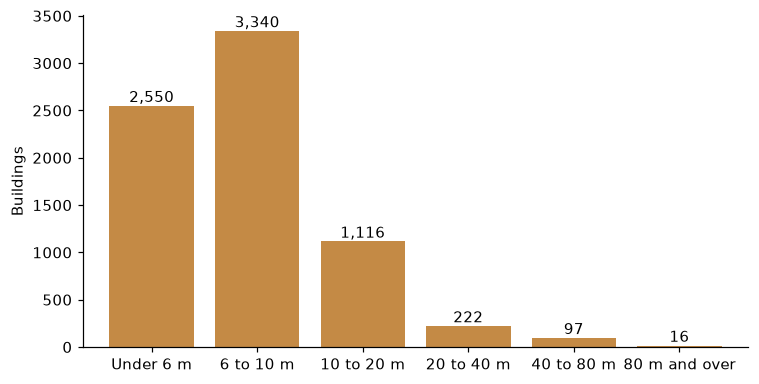

In [5]:
edges = [0, 6, 10, 20, 40, 80, 1000]; labels = ['Under 6 m', '6 to 10 m', '10 to 20 m', '20 to 40 m', '40 to 80 m', '80 m and over']
b['band'] = pd.cut(b.height_m, edges, labels=labels, right=False)
bands = b.band.value_counts().reindex(labels)
print('median height', b.height_m.median(), 'm;', round(100 * (b.height_m < 10).mean()), '% under 10 m;', (b.height_m >= 30).sum(), 'of 30 m or more;', (b.height_m >= 100).sum(), 'of 100 m or more')
ax = bands.plot.bar(color='#c48a45', width=0.8, figsize=(7, 3.6)); ax.set_xlabel(''); ax.set_ylabel('Buildings'); plt.xticks(rotation=0)
for i, v in enumerate(bands): ax.text(i, v + 40, f'{v:,}', ha='center')
plt.tight_layout()

In [6]:
b.groupby('suburb').agg(buildings=('key', 'size'), median_m=('height_m', 'median'), of_30m_or_more=('height_m', lambda s: (s >= 30).sum()), tallest_m=('height_m', 'max'))

,buildings,median_m,of_30m_or_more,tallest_m
suburb,,,,
Adelaide,4613,7.0,171,138.0
North Adelaide,2728,6.4,8,51.0


In [7]:
b.sort_values('height_m', ascending=False)[['name', 'height_m', 'height_from', 'levels']].head(10)

,name,height_m,height_from,levels
0,The Adelaidean,138.0,OpenStreetMap height,37.0
1,RAA Place,132.0,OpenStreetMap height,31.0
2,Realm Adelaide,132.0,OpenStreetMap height,40.0
3,Victoria Tower,121.0,OpenStreetMap height,36.0
4,The Switch,119.0,OpenStreetMap height,35.0
5,Yugo,119.0,OpenStreetMap height,35.0
6,Festival Tower,115.0,OpenStreetMap height,29.0
7,BDO Place,104.0,OpenStreetMap height,24.0
8,Grenfell Centre,103.0,OpenStreetMap height,26.0
9,Kodo,103.0,OpenStreetMap height,32.0


The estimates are for buildings the model does not cover and OpenStreetMap gives no height or levels for. None is tall.

In [8]:
est = b[b.height_from == 'Estimate']
print(len(est), 'estimated;', 'tallest', est.height_m.max(), 'm; median outline', est.area_m2.median(), 'm2 against', b[b.height_from != 'Estimate'].area_m2.median(), 'm2 for the rest')

689 estimated; tallest 20.0 m; median outline 187.0 m2 against 181.0 m2 for the rest


## The shapes

`buildings.geojson` holds the outlines as they are drawn in 3D: one shape a building, or one a mapped part where a
building has them, each with `height_m` and the `base_m` it stands on.

7443 shapes of 7341 buildings


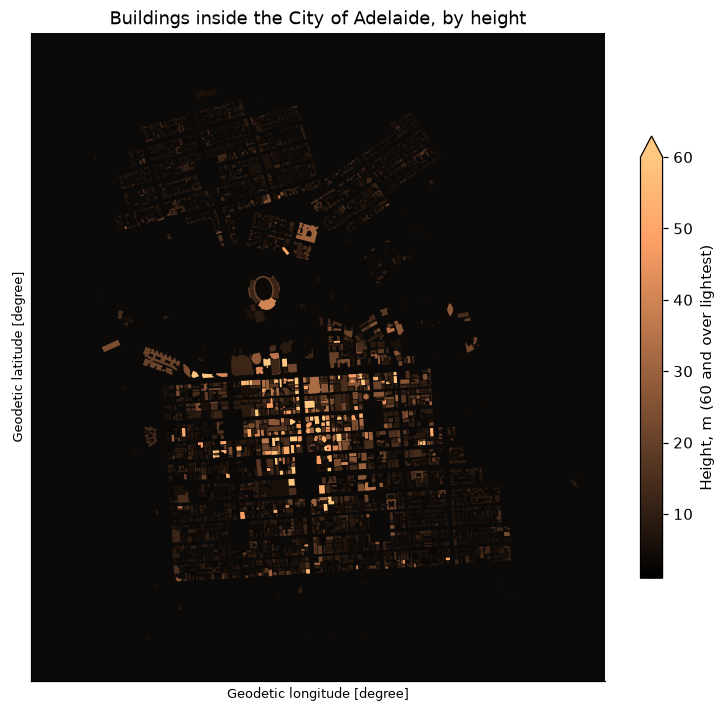

In [9]:
g = gpd.read_file(f'{DATA}/buildings.geojson')
print(len(g), 'shapes of', g.building.nunique(), 'buildings')
ax = g.plot(column='height_m', cmap='copper', figsize=(7, 7), vmax=60, legend=True, legend_kwds={'label': 'Height, m (60 and over lightest)', 'shrink': 0.6})
ax.set_facecolor('#0c0a08'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title('Buildings inside the City of Adelaide, by height')
plt.tight_layout()

Outlines: (c) OpenStreetMap contributors, Open Database Licence. Heights: OpenStreetMap, and the 3D Model of the City
of Adelaide (City of Adelaide, Data.SA, CC BY).